<center><h1>Blackburn_Brianna_HW4</h1></center>
<br>
<br>

Name: Brianna Blackburn
<br>
Github Username: BlackburnBC
<br>
USC ID: 9006039317

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from pathlib import Path
from zipfile import ZipFile
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFECV
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score, roc_curve
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import label_binarize
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score


Get the AReM Data Set

In [3]:
#Set localized file path of zipped folder
data_path = Path("C:/Users/bb76060/OneDrive - University of Southern California/"
    "Documents/Grad School/DSCI-552/HW3/"
    "activity+recognition+system+based+on+multisensor+data+fusion+arem.zip")

extract_path = data_path.parent / "AReM"

with ZipFile(data_path, "r") as zip_file:
    zip_file.extractall(extract_path)

#Establish activity categories
activity_type = ["bending1","bending2","cycling","lying","sitting","standing","walking"]

data_folders = {activity: next((folder
            for folder in extract_path.rglob(activity)
            if folder.is_dir()),None)
    for activity in activity_type}

all_files = list(extract_path.rglob("dataset*.csv"))

#Establish the time series data activities and column headers
sensor_series = ["avg_rss12","var_rss12","avg_rss13","var_rss13","avg_rss23","var_rss23"]
col_names = ["time"] + sensor_series

#Clean datafiles: remove blank and duplicate rows, uniform CSV comma separated, uniform numeric values
def data_cleaning(file):
  
    data = pd.read_csv(file, comment="#", header=None, sep=r"[,\s]+", engine="python", usecols=range(7))
    data = data.dropna(how="all")
    data.columns = col_names
    data = data.apply(pd.to_numeric, errors="coerce")
    data = data.sort_values("time")
    data = data.drop_duplicates(subset="time")
    data = data.reset_index() #Move "time" into column positioning

    #Missing time values in Sitting folde for dataset8
    #Use interpolate function to estimate row values for time sequence 13500
    expected_time = np.arange(0, 120000, 250)
    data = data.set_index("time").reindex(expected_time)
    data[sensor_series] = data[sensor_series].interpolate(method="linear")

    return data

### (b) Splitting Data

In [4]:
#Folder paths within zipped folder
activity_folders = [folder
    for folder in extract_path.rglob("*")
    if folder.is_dir() and folder.name in activity_type]

bending_folders = ["bending1", "bending2"]

#Loop for reading in and saving datafiles and categorizing them between the training and test datasets
train_files = []
test_files = []

for folder in activity_folders:

    for file in folder.glob("dataset*.csv"):

        dataset_number = int(file.stem.replace("dataset", ""))

        is_bending_test = (folder.name in ["bending1", "bending2"]
            and dataset_number in [1, 2])
        is_other_test = (folder.name not in ["bending1", "bending2"]
            and dataset_number in [1, 2, 3])

        if is_bending_test or is_other_test:
            test_files.append(file)
        else:
            train_files.append(file)

#Sort activity type in logical numeric order for dataset structure
activity_order = {activity: position
    for position, activity in enumerate(activity_type)}

all_data = sorted(train_files + test_files,
    key=lambda file: (activity_order[file.parent.name],
        int(file.stem.replace("dataset", ""))))


### (c) Feature Extraction

In [5]:
#Create loop to read each file, assign column headers, and create 7 statistical features
# Read each file and calculate the 42 statistical features
feature_calcs = []

test_file_set = set(test_files)

for instance, file in enumerate(all_data, start=1):
    data = data_cleaning(file)

    #Create one row for the current instance
    row = {"Instance": instance, "Activity": file.parent.name, "Dataset": file.name,
        "Split": "test" if file in test_file_set else "train"}

    #Calculate new features and append each row to bottom 
    for number, column in enumerate(sensor_series, start=1):

        row[f"min{number}"] = data[column].min()
        row[f"max{number}"] = data[column].max()
        row[f"mean{number}"] = data[column].mean()
        row[f"median{number}"] = data[column].median()
        row[f"std{number}"] = data[column].std()
        row[f"1st_quart{number}"] = data[column].quantile(0.25)
        row[f"3rd_quart{number}"] = data[column].quantile(0.75)

    feature_calcs.append(row)

#Convert all dataset and new features into dataframe
df_feature_calcs = pd.DataFrame(feature_calcs)

#Fixed from HW3 
feature_columns = [
    column
    for column in df_feature_calcs.columns
    if column not in ["Instance", "Activity", "Dataset", "Split"]]

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

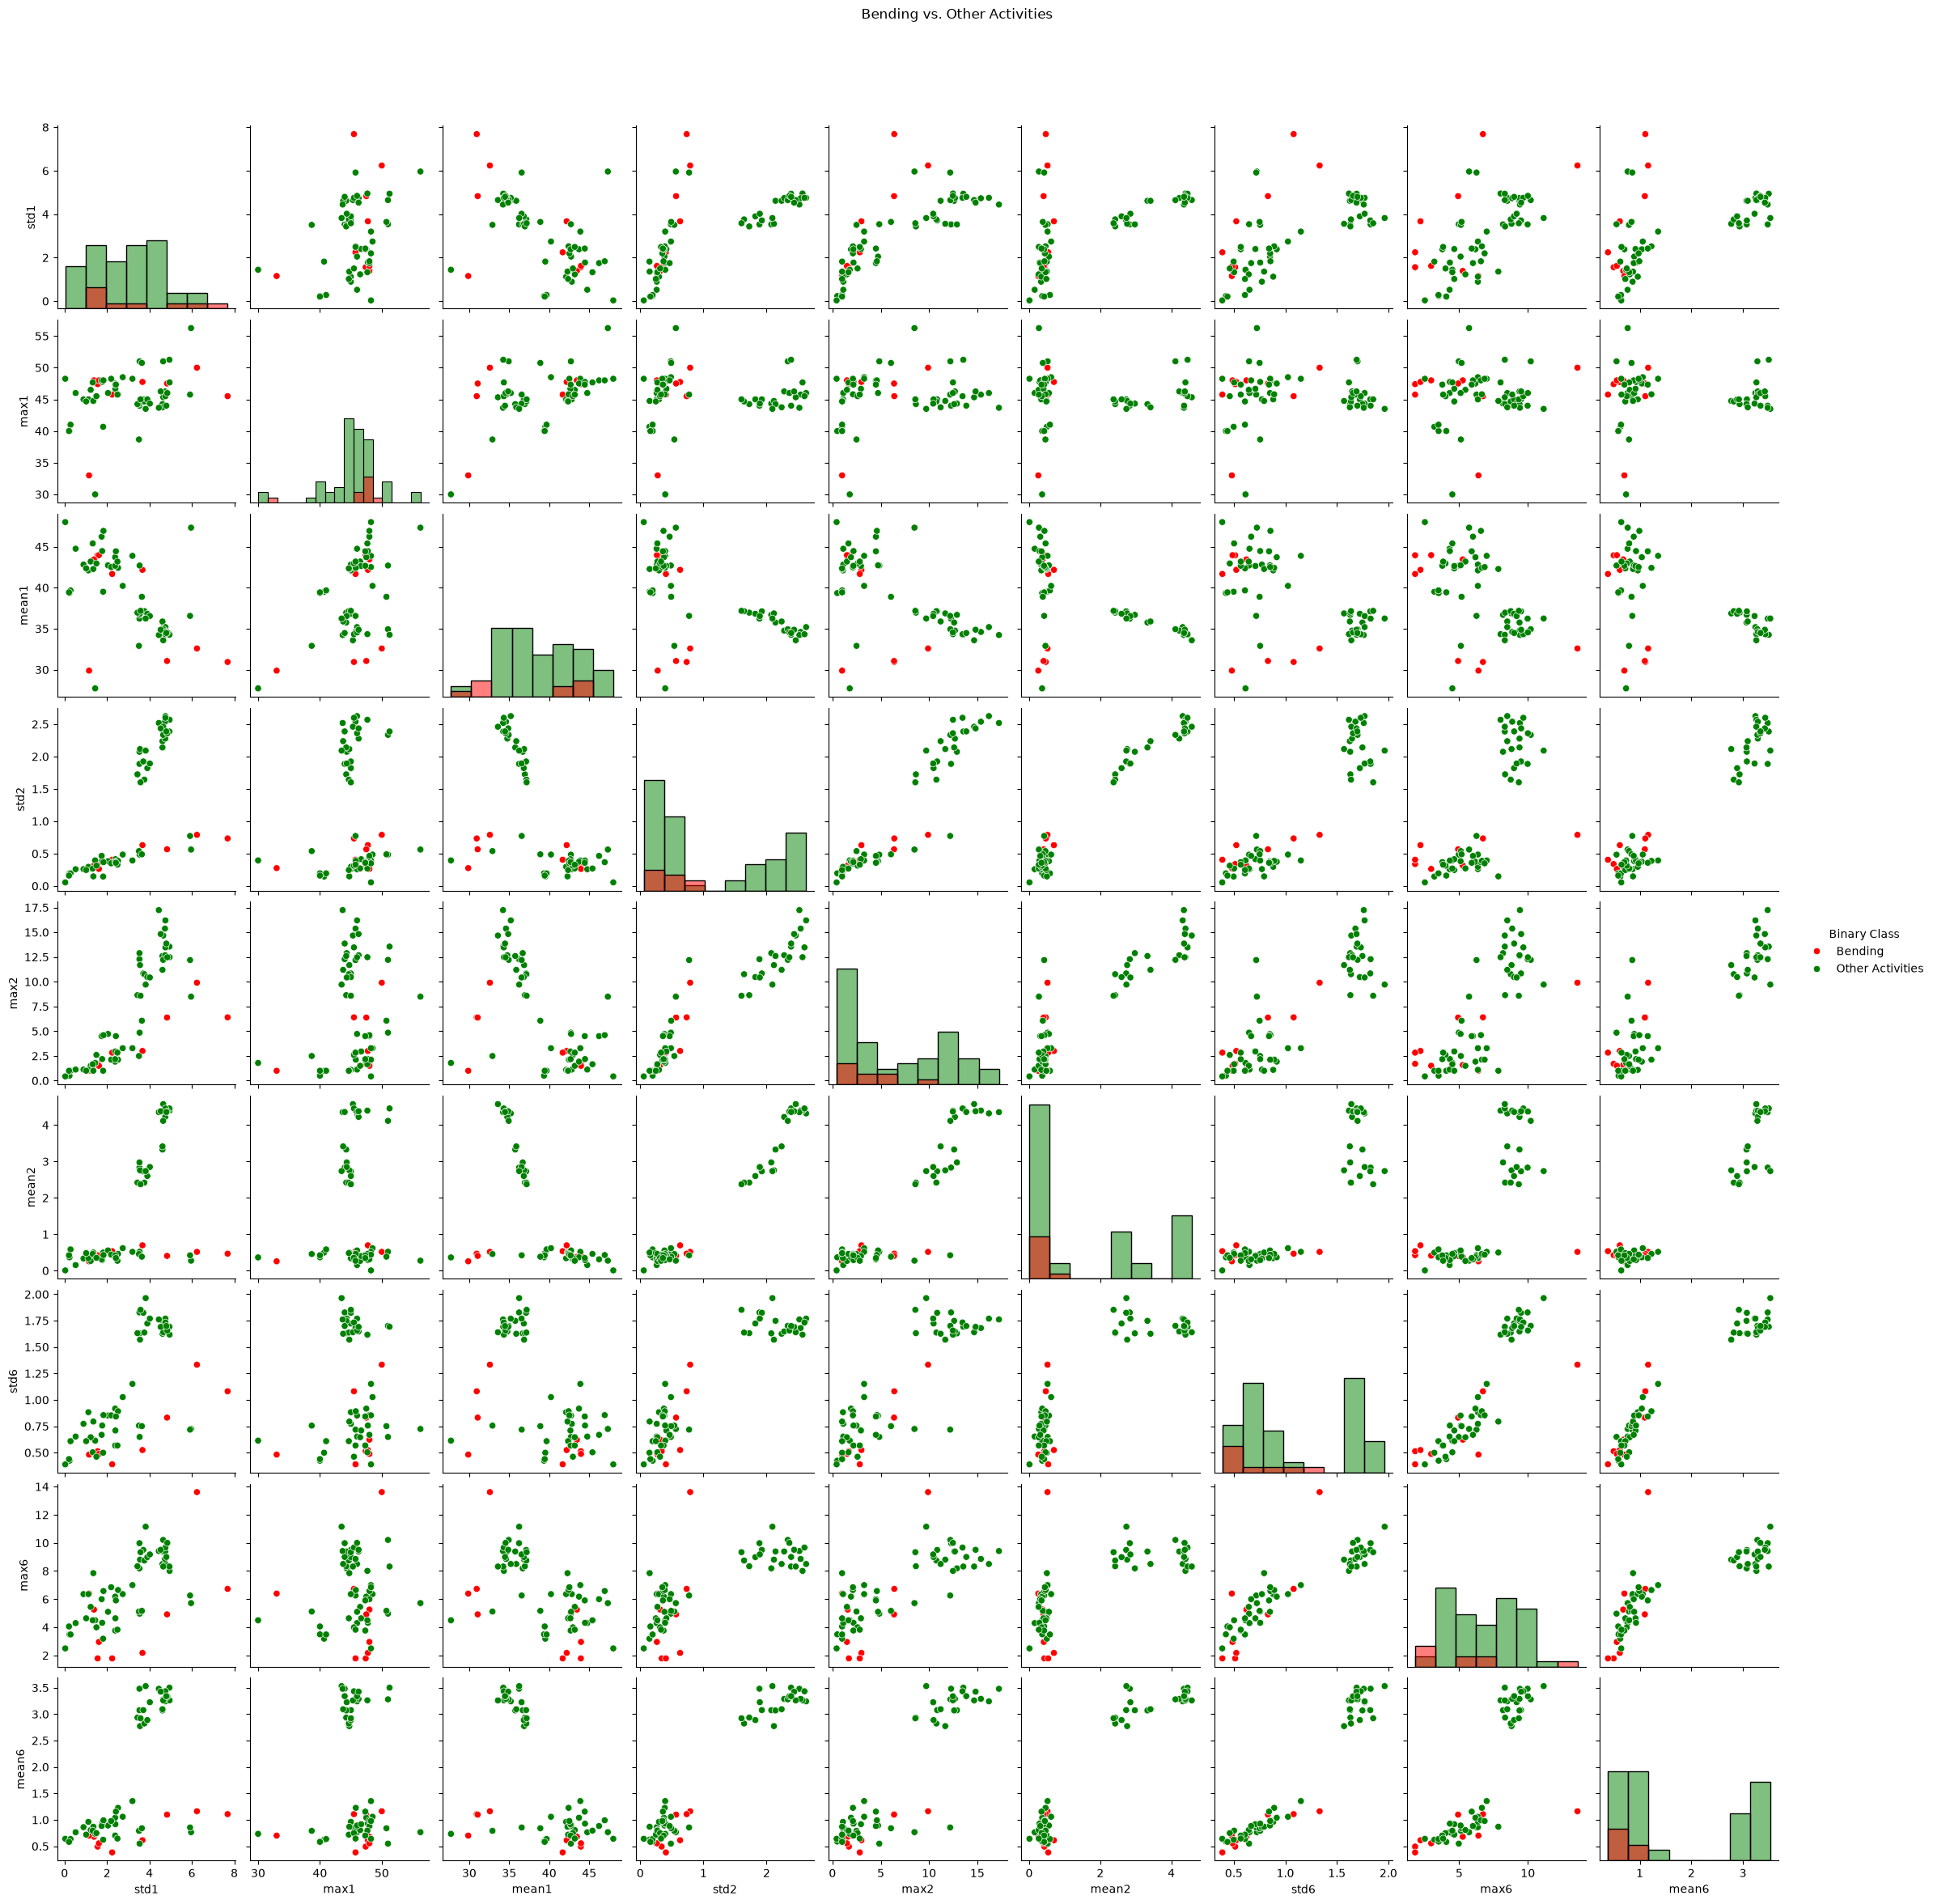

In [6]:
#Logistic regression model for now binary class problem
#No penalty per footnote 3 in assignment prompt 2a instead of C infinity
log_model = LogisticRegression(penalty = None, solver = "lbfgs", max_iter = 10000)

log_train = df_feature_calcs[ df_feature_calcs["Split"] == "train"].copy()

#Create binary distincxiton between bending features and all other activities
log_train["Binary Class"] = np.where(log_train["Activity"].isin(["bending1", "bending2"]),
                                     "Bending", "Other Activities")

#Selected features from HW3 = Standard Deviation, Max, and Mean
selected_features = ["std1", "max1", "mean1", "std2", "max2", "mean2","std6", "max6", "mean6"]

#Scatterplots showing binary relationships
sns.pairplot(data = log_train, vars = selected_features, hue = "Binary Class",
    palette={"Bending": "red", "Other Activities": "green"}, diag_kind = "hist")

plt.suptitle("Bending vs. Other Activities", y = 1.05)
plt.show()

#### ii. Splitted Plots

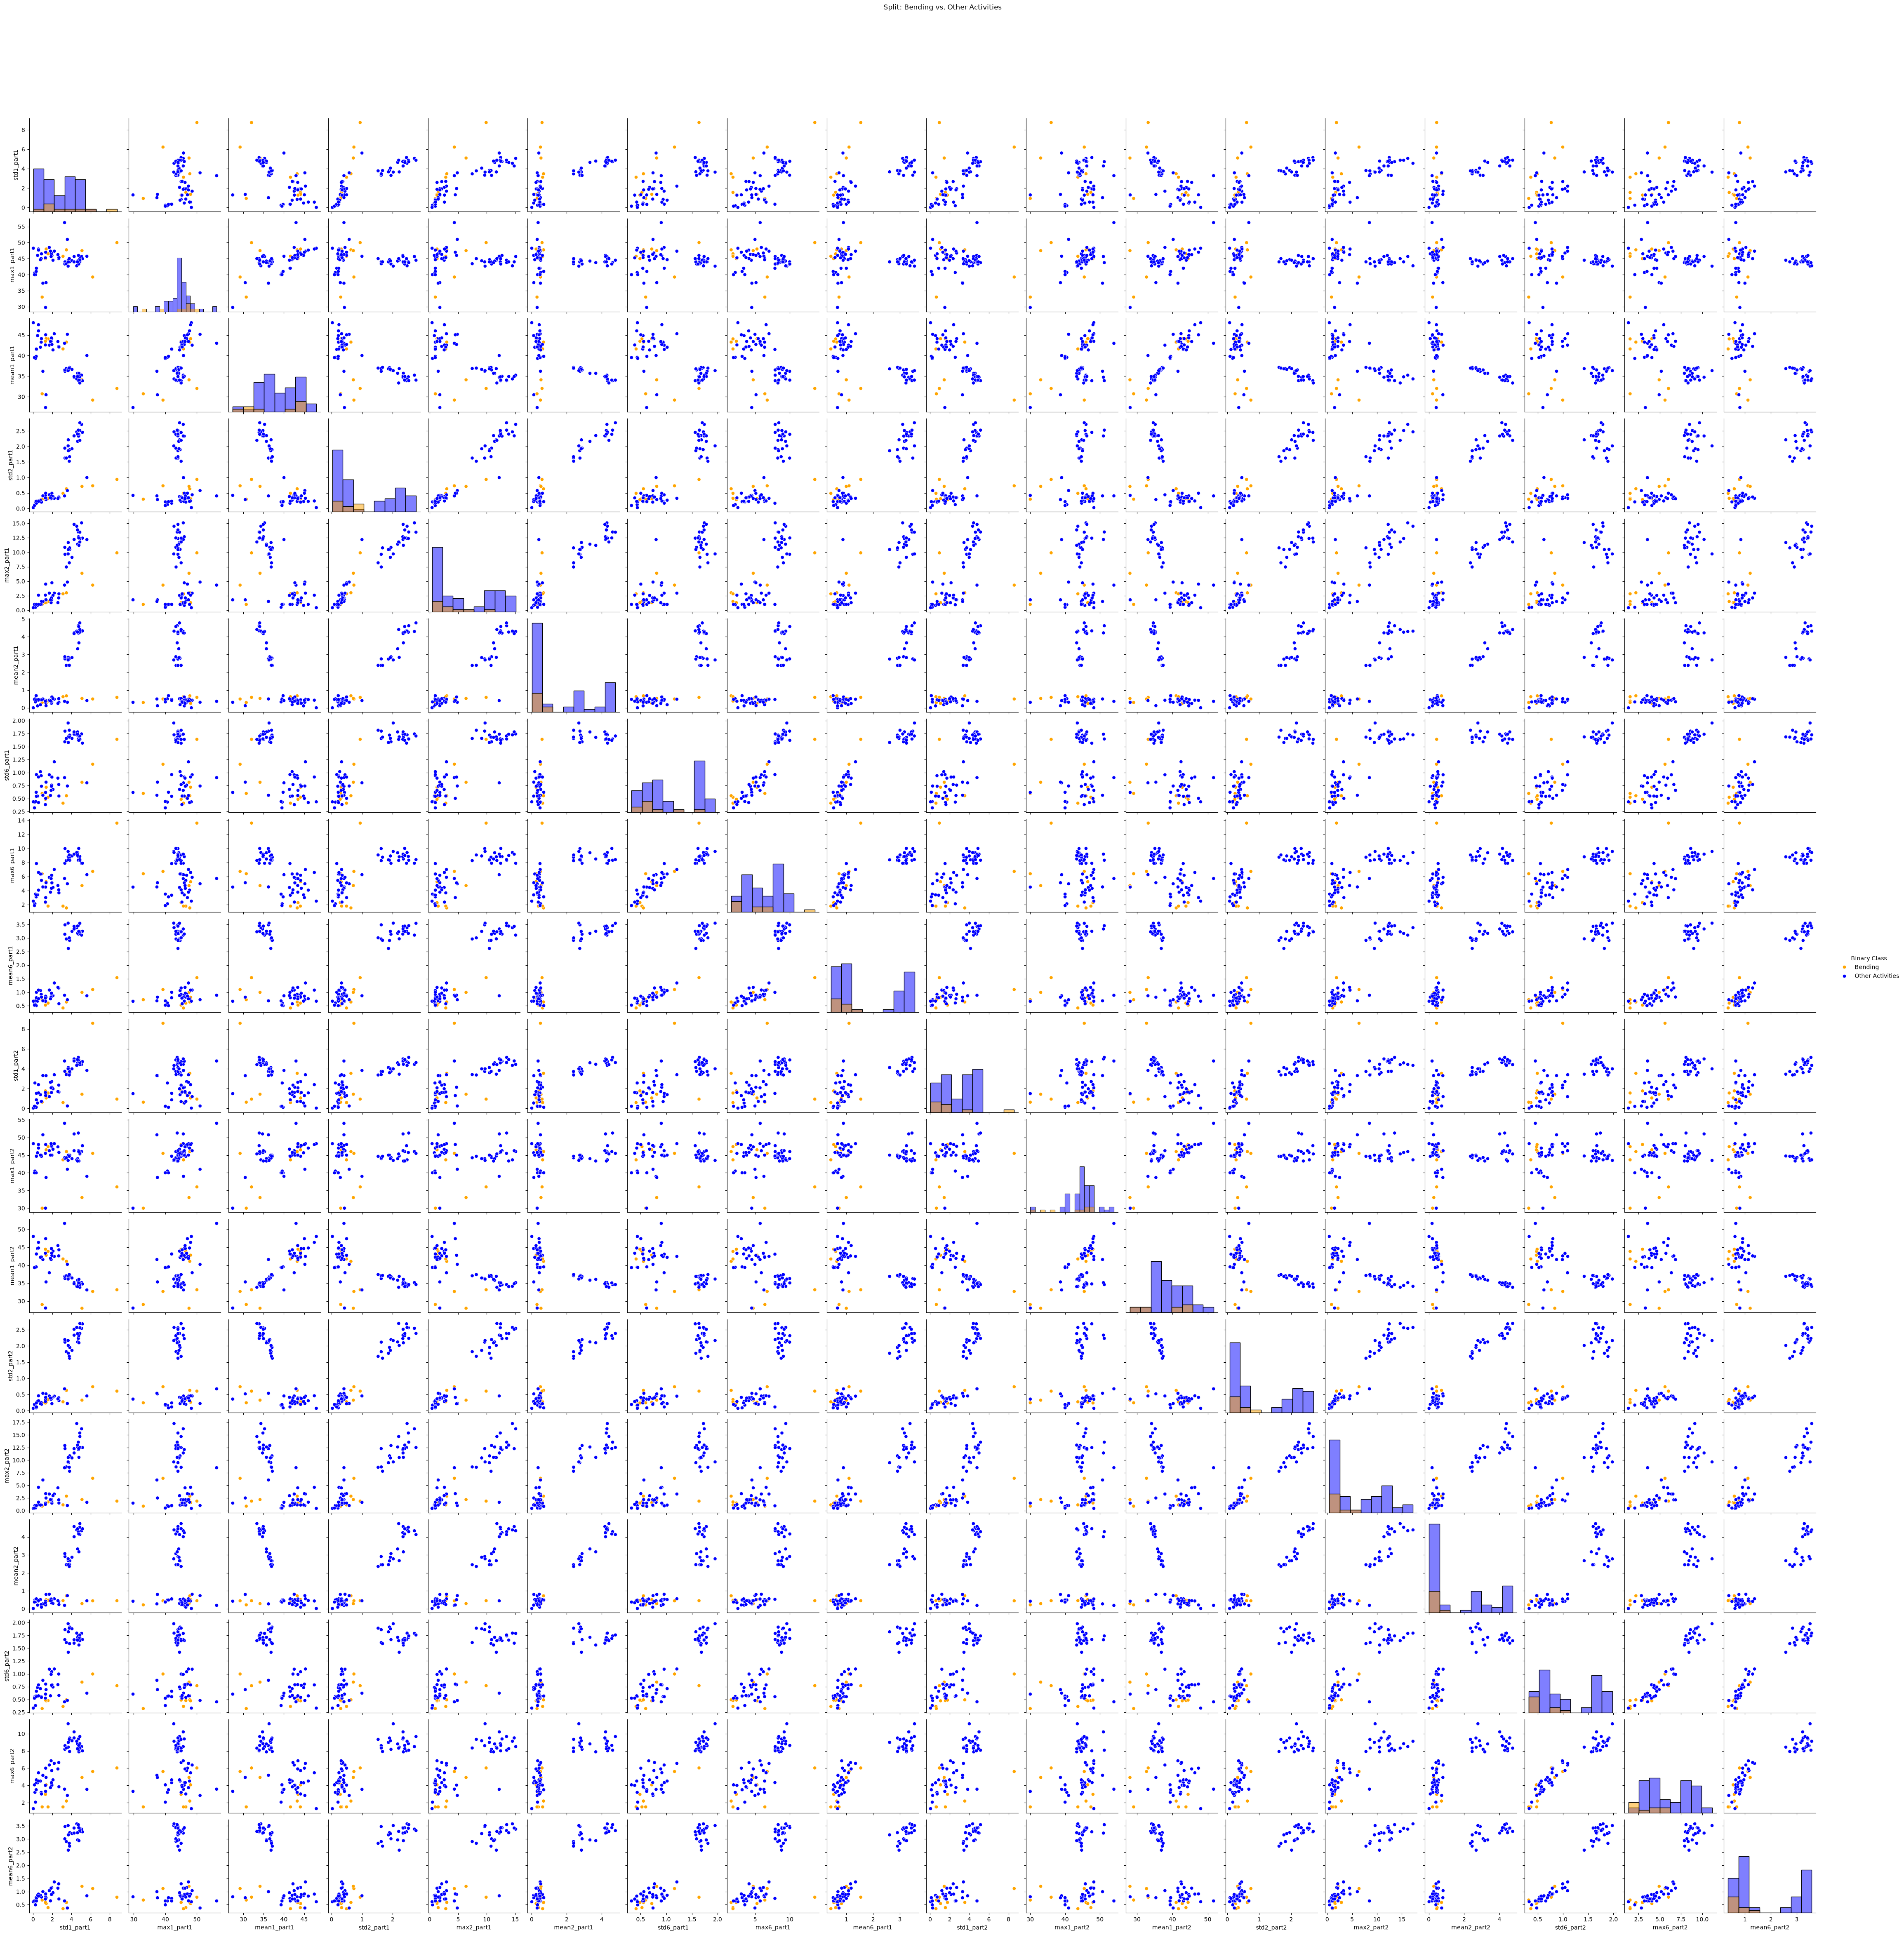

In [7]:
#Loop through splitting each training set instances and sort logical order to match original 
selected_feature_split = []

sorted_train = sorted(train_files,
    key=lambda file: (activity_order[file.parent.name],
        int(file.stem.replace("dataset", ""))))

for instance, file in enumerate(sorted_train, start=1):
    data = data_cleaning(file)
    midpoint = len(data) // 2 
    segments = {"part1": data.iloc[:midpoint], "part2": data.iloc[midpoint:]}

    #Each training instance
    row = {"Instance": instance, "Activity": file.parent.name, "Dataset": file.name}

    #Calc selected features for each series = Std, Mean, Max
    for part_name, segment in segments.items():

        for series_number in [1, 2, 6]:

            sensor_column = sensor_series[series_number - 1]

            row[f"std{series_number}_{part_name}"] = (segment[sensor_column].std())
            row[f"max{series_number}_{part_name}"] = (segment[sensor_column].max())
            row[f"mean{series_number}_{part_name}"] = (segment[sensor_column].mean())

    selected_feature_split.append(row)

#Split features calc dataframe 
df_split_features = pd.DataFrame(selected_feature_split)

#Again create binary distincxiton between bending features and all other activities
df_split_features["Binary Class"] = np.where(df_split_features["Activity"].isin(["bending1", "bending2"]),
    "Bending","Other Activities")

df_split_features

split_selected_features = [f"{feature}{series}_{part}"
    for part in ["part1", "part2"]
    for series in [1, 2, 6]
    for feature in ["std", "max", "mean"]]

split_selected_features

sns.pairplot(data = df_split_features, vars = split_selected_features, hue = "Binary Class",
    palette={"Bending": "orange", "Other Activities": "blue"}, diag_kind = "hist")

plt.suptitle("Split: Bending vs. Other Activities", y = 1.05)
plt.show()

Answer: Just from a rough visual observation, it looks like there is no considerable difference in the results from prior to post splitting the series instances. I am still seeing similar distribution and relationships, imbalances and shapes etc. 

#### iii. Time Series Segments

In [8]:
#Calculate time series features 
def calc_features(series):
    return {"min": series.min(), "max": series.max(), "mean": series.mean(), "median": series.median(),
        "std": series.std(), "1st_quart": series.quantile(0.25), "3rd_quart": series.quantile(0.75)}

#Loop through creating equal series segments with predictors outputted into a dataframe
def segmented_features(files, number_of_segments):
    feature_rows = []
    sorted_files = sorted(files, key = lambda file: (activity_order[file.parent.name],
            int(file.stem.replace("dataset", " "))))

    for instance, file in enumerate(sorted_files, start = 1):
        data = data_cleaning(file)
        segments = np.array_split(data, number_of_segments)
        row = {"Instance": instance, "Activity": file.parent.name, "Dataset": file.name}

        for segment_number, segment in enumerate(segments, start = 1):

            for series_number, sensor_column in enumerate(sensor_series, start = 1):
                feature_values = calc_features(segment[sensor_column])

                for feature_name, feature_value in feature_values.items():
                    column_name = (f"{feature_name}{series_number}"
                        f"_segment{segment_number}")
                    row[column_name] = feature_value
        feature_rows.append(row)

    feature_df = pd.DataFrame(feature_rows)

    #Binary classificaiton label (bending vs oyher activities)
    feature_df["Binary Class"] = np.where(feature_df["Activity"].isin(["bending1", "bending2"]), 1, 0)
    return feature_df

#Run stratified 5-fold cross validation to distribute bending instances evenly among folds
#Class imlabance breakdown 0 = 60 and 1 = 9 
#Chose random state seed 42 just as common practice
cv_5fold = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

#Logistic regression for RFE
#####Chose max iteration 1000
log_model = LogisticRegression(C = np.inf, solver = "lbfgs", max_iter = 1000)

model_pipeline = Pipeline([("scaler", StandardScaler()), ("classifier", log_model)])

#Loops through all iterations of l and predictors
results = []

best_score = -1
best_l = None
best_p = None
best_rfecv = None
best_X = None
best_y = None

#Loop through range 1 through 20
for l in range(1, 21):
    feature_df = segmented_features(train_files, number_of_segments = l)

    X = feature_df.drop(columns = ["Instance", "Activity", "Dataset", "Binary Class"])
    y = feature_df["Binary Class"]

    #Find best # of predictors
    rfecv = RFECV(estimator = model_pipeline, step = 1, min_features_to_select = 1,
        cv = cv_5fold, scoring = "accuracy", n_jobs = -1,
        importance_getter = "named_steps.classifier.coef_")
    rfecv.fit(X, y)

    p = rfecv.n_features_
    score = rfecv.cv_results_["mean_test_score"].max()

    results.append({"l": l, "Predictors": p, "CV Accuracy": score})

    #Highlight best model scores 
    if score > best_score:
        best_score = score
        best_l = l
        best_p = p
        best_rfecv = rfecv
        best_X = X
        best_y = y

cv_results_df = pd.DataFrame(results)
cv_results_df

print("Best l:", best_l)
print("Best Predictors:", best_p)
print("Best CV Accuracy:", round(best_score, 4))

final_selected_features = best_X.columns[best_rfecv.support_].tolist()
final_selected_features

C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:117

Best l: 20
Best Predictors: 6
Best CV Accuracy: 1.0


C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:117

['mean5_segment3',
 'median5_segment3',
 '1st_quart5_segment3',
 '3rd_quart1_segment12',
 'std3_segment16',
 'min5_segment18']

#### iv. Confusion Matrix

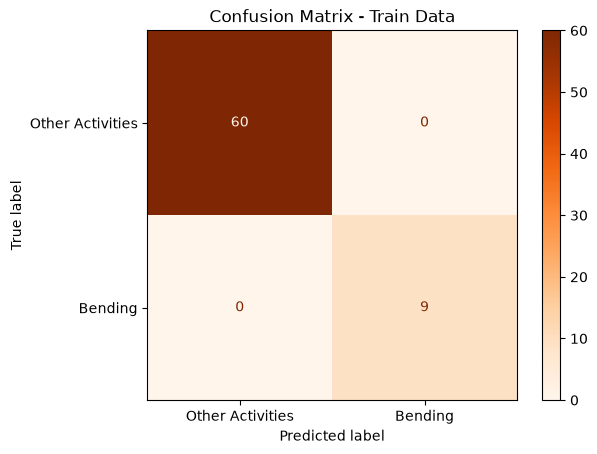

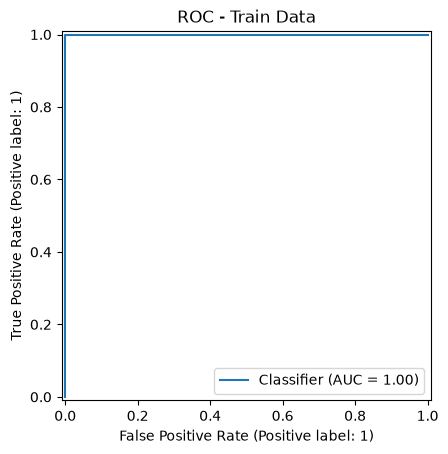

AUC - Train Data: 1.0
scikit-learn coefficients


,Parameter,Coefficient
0,Intercept,-11.539199
1,mean5_segment3,2.694105
2,median5_segment3,2.222620
3,1st_quart5_segment3,4.605096
4,3rd_quart1_segment12,-2.346789
5,std3_segment16,-2.703254
6,min5_segment18,2.801022


statsmodels values


C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python3

,Coefficient,p-value
const,-37.116512,0.999948
mean5_segment3,12.588846,0.999999
median5_segment3,-8.345231,0.999999
1st_quart5_segment3,27.337169,0.999992
3rd_quart1_segment12,-7.161483,0.999990
std3_segment16,-10.314922,0.999991
min5_segment18,6.754733,0.999993


In [9]:
#Training data log model predictions
y_train_pred = best_rfecv.predict(best_X)
y_train_prob = best_rfecv.predict_proba(best_X)[:, 1]

#Confusion Matrix
ConfusionMatrixDisplay.from_predictions(best_y, y_train_pred,
    display_labels=["Other Activities", "Bending"], cmap="Oranges")

plt.title("Confusion Matrix - Train Data")
plt.show()

#ROC results
RocCurveDisplay.from_predictions(best_y, y_train_prob)

plt.title("ROC - Train Data")
plt.show()

print("AUC - Train Data:", roc_auc_score(best_y, y_train_prob))

#Best predictors selected through RFE
RFE_features = best_X.columns[best_rfecv.support_]

#Fitted logistic regression inside RFECV
fitted_pipeline = best_rfecv.estimator_
fitted_log_model = fitted_pipeline.named_steps["classifier"]

#Coefficients using scikit-learn
coeff_df = pd.DataFrame({"Parameter": ["Intercept"] + RFE_features.tolist(),
    "Coefficient": np.r_[fitted_log_model.intercept_, fitted_log_model.coef_.ravel()]})
print("scikit-learn coefficients")
display(coeff_df)

#Selected predictors with fitted scaler
X_selected = best_X.loc[:, RFE_features]
X_scaled = fitted_pipeline.named_steps["scaler"].transform(X_selected)

X_scaled = pd.DataFrame(X_scaled, columns = RFE_features, index = best_X.index)

#Intercept
X_stats = sm.add_constant(X_scaled, has_constant = "add")

#Coefficients and their p-values using statsmodels
stats_model = sm.Logit(best_y, X_stats).fit(maxiter = 1000, disp = False)

model_results = pd.DataFrame({"Coefficient": stats_model.params, "p-value": stats_model.pvalues})
print("statsmodels values")
display(model_results)


#### v. Test Classifier

In [10]:
#Test classification model on test data
#Segment test series data using best l variable
test_feature_df = segmented_features(test_files, number_of_segments = best_l)

X_test = test_feature_df.drop(columns=["Instance", "Activity", "Dataset", "Binary Class"])
y_test = test_feature_df["Binary Class"]

#Order test predictors to match previous training predictor order
X_test = X_test.loc[:, best_X.columns]

#Implement bexst fitted feature parameters
y_test_pred = best_rfecv.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Cross-validation accuracy: {best_score:.2%}")
print(f"Test accuracy: {test_accuracy:.2%}")

Cross-validation accuracy: 100.00%
Test accuracy: 94.74%


#### vi. Separation

Answer: Based on model performance the classes are well separated enough to be correctly classified (given just a tiny decrease in test performance). So with this, we saw a difference between scikit-learn and statsmodels coefficients. This is a tell that instability is a factor with the logistic regression parameters. Unregularized model can produce coefficients that continue growing, rendering them as unreliable.  

#### vii. Imbalance

C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


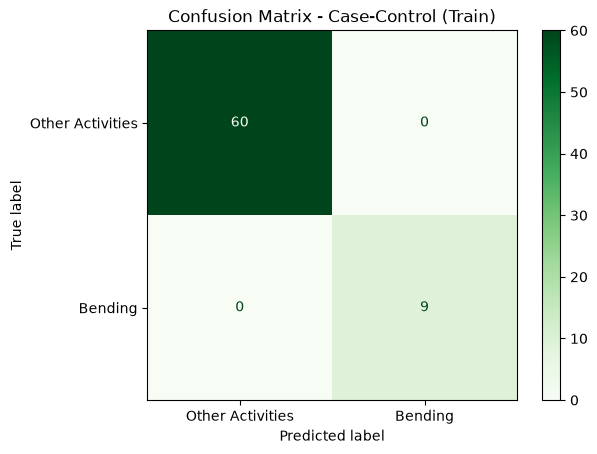

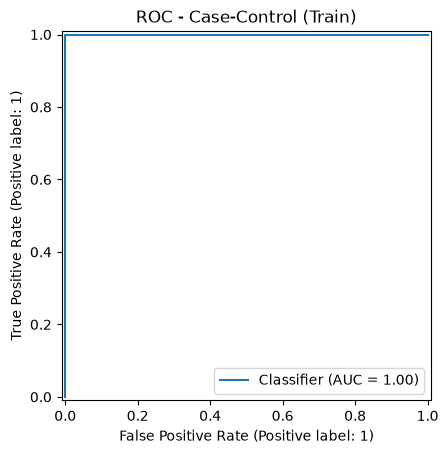

Training CC AUC: 1.0


In [11]:
#RFE chosen predictors
features = best_X.columns[best_rfecv.support_]

#All 9 bending instances stay and only 9 other activity instances are randomly selected
case_control_y = pd.concat([best_y[best_y == 1], best_y[best_y == 0].sample(
        n=(best_y == 1).sum(),random_state=42)])
case_control_X = best_X.loc[case_control_y.index, features]

#Fit case-control sampling log model
case_control_model = Pipeline([("scaler", StandardScaler()),("classifier", LogisticRegression(
        C = np.inf, solver = "lbfgs", max_iter = 1000))])
case_control_model.fit(case_control_X, case_control_y)

#Original class proportions adjusted
class_proportion = best_y.mean()

case_control_model.named_steps["classifier"].intercept_ += (np.log(class_proportion / (1 - class_proportion)))

#Evaluate on training series
X_train = best_X.loc[:, features]

cc_predictions = case_control_model.predict(X_train)
cc_probabilities = case_control_model.predict_proba(X_train)[:, 1]

ConfusionMatrixDisplay.from_predictions(best_y, cc_predictions, 
                                        display_labels = ["Other Activities", "Bending"], cmap = "Greens")
plt.title("Confusion Matrix - Case-Control (Train)")
plt.show()

RocCurveDisplay.from_predictions(best_y, cc_probabilities)
plt.title("ROC - Case-Control (Train)")
plt.show()
print("Training CC AUC:", roc_auc_score(best_y, cc_probabilities))

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [12]:
#Penalized logistic regression model with standardization of features using mean 0 & std 1 appromixator
l1_model_pipeline = Pipeline([("scaler", StandardScaler()),
    ("classifier", LogisticRegression(l1_ratio = 1, solver = "liblinear", max_iter = 10000, random_state = 42))])

#Loop through each l value in range and note best scores of all runs
l1_model_results = []
best_l1_score = -1

for l in range(1, 21):

    feature_df = segmented_features(train_files, number_of_segments=l)
    X = feature_df.drop(columns=["Instance", "Activity", "Dataset", "Binary Class"])
    y = feature_df["Binary Class"]

    search = GridSearchCV(estimator = l1_model_pipeline, param_grid = {"classifier__C": np.logspace(-4, 4, 9)},
        cv = cv_5fold, scoring = "accuracy")
    search.fit(X, y)

    l1_model_results.append({"l": l, "C": search.best_params_["classifier__C"], 
                            "CV Accuracy": search.best_score_})

    if search.best_score_ > best_l1_score:
        best_l1_score = search.best_score_
        best_l1_l = l
        best_l1_C = search.best_params_["classifier__C"]
        best_l1_model = search.best_estimator_
        best_l1_X = X
        best_l1_y = y

display(pd.DataFrame(l1_model_results))

print("Best Performance Scores:")
print("l = ", best_l1_l)
print("C = ", best_l1_C)
print("CV accuracy = ", round(best_l1_score, 4))

#Selected predictors with non-zero coefficients
coefficients = best_l1_model.named_steps["classifier"].coef_[0]

selected_l1_features = pd.DataFrame({"Feature": best_l1_X.columns, "Coefficient": coefficients})
selected_l1_features = selected_l1_features[selected_l1_features["Coefficient"] != 0]

display(selected_l1_features)
print("Number of selected features = ", len(selected_l1_features))

,l,C,CV Accuracy
0,1,10000.0,0.971429
1,2,1.0,0.957143
2,3,1.0,0.957143
3,4,1.0,0.957143
4,5,10.0,0.927473
5,6,100.0,0.957143
6,7,1.0,0.927473
7,8,1000.0,0.942857
8,9,10000.0,0.928571
9,10,100.0,0.971429


Best Performance Scores:
l =  19
C =  1.0
CV accuracy =  0.9857


,Feature,Coefficient
70,min5_segment2,0.046175
112,min5_segment3,0.035140
117,1st_quart5_segment3,2.119631
197,max5_segment5,0.018525
421,max1_segment11,-0.572357
571,std4_segment14,-0.056338
627,std6_segment15,-0.214442
700,min5_segment17,0.619932
746,std5_segment18,-0.075019
750,max6_segment18,-0.118856


Number of selected features =  10


#### ii. Comparison

Answer: The l1-penalized logistic regression model was a more simplified and straightforward implementation compared to using p-value based feature selection with the RFE model. Leveraging the penalty streamlined model fit and feature selection whereas the p-value observation method required more intervention with refitting and weeding out predictors. The most important aspect is the influence on p-values that the RFE model created because of the separation which made that measurement unreliable. Although, technically the RFE model achieved better cross validation accuracy compared to the l1 penalized model, but by the smallest margin. I would go with l1-panelized logistic regression with standardization and liblinear specifically. 

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python3

,l,C,CV Accuracy
0,1,1.0,0.900000
1,2,100.0,0.883516
2,3,1000.0,0.885714
3,4,1000.0,0.900000
4,5,100.0,0.885714
5,6,10000.0,0.914286
6,7,1000.0,0.884615
7,8,1000.0,0.898901
8,9,10000.0,0.871429
9,10,1000.0,0.856044


Best Multi Nomial Performance Scores:
l =  6
C =  10000.0
CV Accuracy =  0.9143
Test Accuracy = 89.47%
Test Error = 10.53%


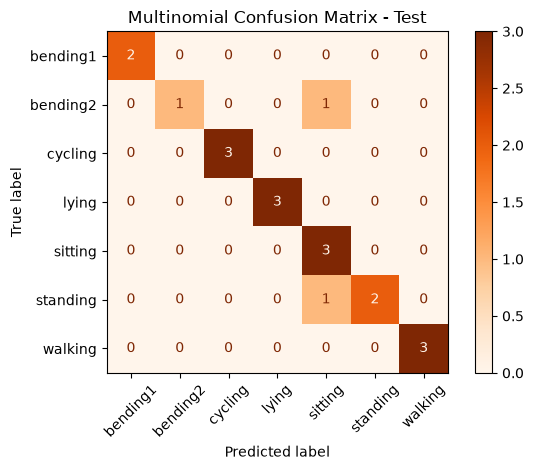

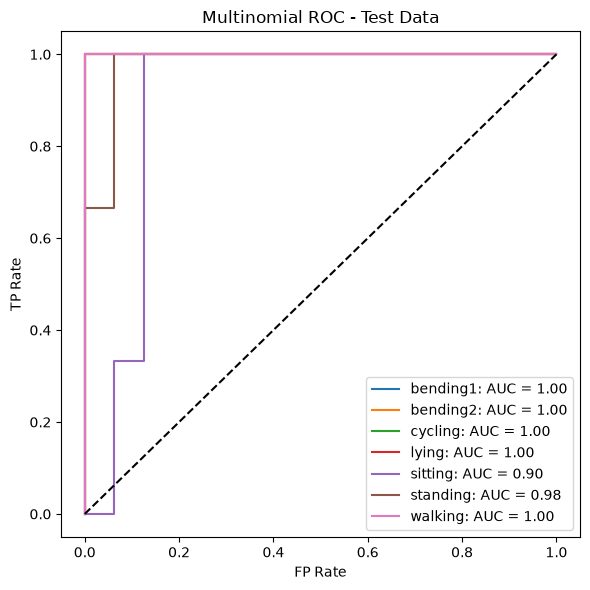

In [13]:
# L1-penalized multinomial logistic regression model
multi_log_pipeline = Pipeline([("scaler", StandardScaler()),
                               ("classifier", LogisticRegression(l1_ratio = 1,solver = "saga", 
                                                                 max_iter = 10000, random_state = 42))])

multi_log_results = []
best_multi_score = -1

for l in range(1, 21):

    feature_df = segmented_features(train_files, number_of_segments=l)
    X = feature_df.drop(columns=["Instance", "Activity", "Dataset", "Binary Class"])
    y = feature_df["Activity"]

    search = GridSearchCV(estimator=multi_log_pipeline, param_grid={"classifier__C": np.logspace(-4, 4, 9)},
                          cv = cv_5fold, scoring = "accuracy", n_jobs = -1)
    search.fit(X, y)

    multi_log_results.append({"l": l, "C": search.best_params_["classifier__C"], "CV Accuracy": search.best_score_})

    if search.best_score_ > best_multi_score:
        best_multi_score = search.best_score_
        best_multi_l = l
        best_multi_C = search.best_params_["classifier__C"]
        best_multi_model = search.best_estimator_
        best_multi_X = X

display(pd.DataFrame(multi_log_results))

print("Best Multi Nomial Performance Scores:")
print("l = ", best_multi_l)
print("C = ", best_multi_C)
print("CV Accuracy = ", round(best_multi_score, 4))

#Calculate multi-nomial logistic model test error
test_multi_df = segmented_features(test_files, number_of_segments = best_multi_l)

X_multi_test = test_multi_df.loc[:, best_multi_X.columns]
y_multi_test = test_multi_df["Activity"]

multi_predictions = best_multi_model.predict(X_multi_test)
multi_probabilities = best_multi_model.predict_proba(X_multi_test)

test_accuracy = accuracy_score(y_multi_test, multi_predictions)

print(f"Test Accuracy = {test_accuracy:.2%}")
print(f"Test Error = {1 - test_accuracy:.2%}")

#Confusion matrix
classes = best_multi_model.classes_

ConfusionMatrixDisplay.from_predictions(y_multi_test, multi_predictions, labels = classes, 
                                        cmap = "Oranges", xticks_rotation = 45)

plt.title("Multinomial Confusion Matrix - Test")
plt.tight_layout()
plt.show()

#ROC Curve
y_test_binary = label_binarize(y_multi_test, classes = classes)

plt.figure(figsize = (6, 6))

for i, activity in enumerate(classes):

    fpr, tpr, _ = roc_curve(y_test_binary[:, i], multi_probabilities[:, i])
    auc = roc_auc_score(y_test_binary[:, i], multi_probabilities[:, i])
    plt.plot(fpr, tpr, label = f"{activity}: AUC = {auc:.2f}")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("FP Rate")
plt.ylabel("TP Rate")
plt.title("Multinomial ROC - Test Data")
plt.legend()
plt.tight_layout()
plt.show()

#### ii. Naive Bayes

C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python3

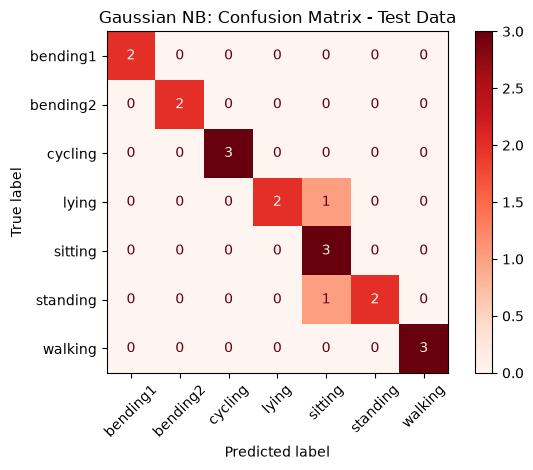

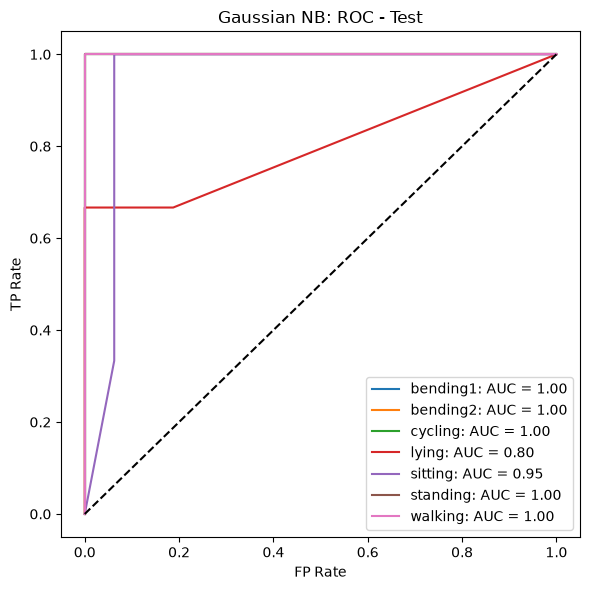

C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\bb76060\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python3

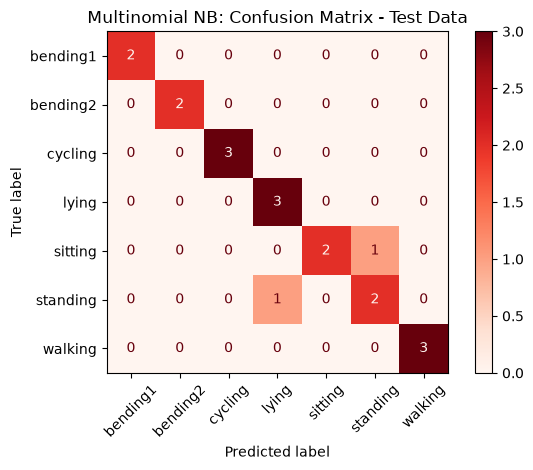

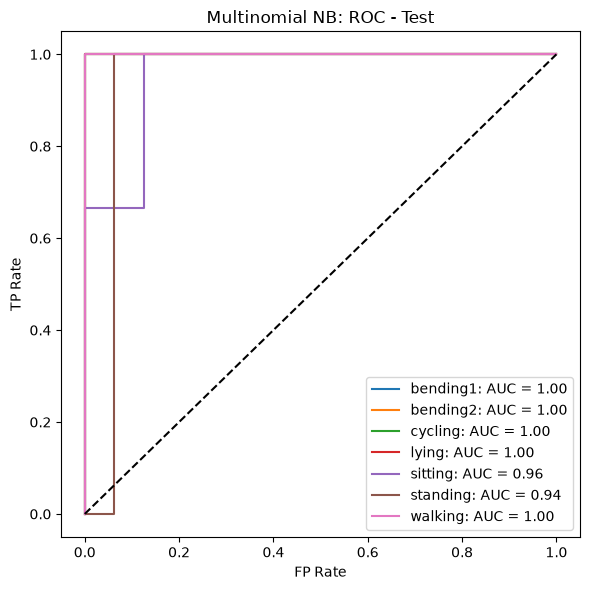

,Model,Best l,CV Accuracy,Test Accuracy,Test Error
0,Gaussian NB,1,0.857143,0.894737,0.105263
1,Multinomial NB,1,0.871429,0.894737,0.105263


In [14]:
#Naive Bayes classifier models - Gaussian and Multinomial priors
naive_results = []
naive_models = {}

for name, model in {"Gaussian NB": GaussianNB(), "Multinomial NB": MultinomialNB()}.items():

    best_score_naive = -1

    for l in range(1, 21):

        feature_df = segmented_features(train_files, number_of_segments = l)
        X = feature_df.drop(columns=["Instance", "Activity", "Dataset", "Binary Class"])
        y = feature_df["Activity"]

        score = cross_val_score(model, X, y, cv = cv_5fold, scoring = "accuracy").mean()

        if score > best_score_naive:
            best_score_naive = score
            best_l_naive = l
            best_X_naive = X
            best_y_naive = y

    model.fit(best_X_naive, best_y_naive)

    test_df = segmented_features(test_files, number_of_segments = best_l_naive)

    X_test_naive = test_df.loc[:, best_X_naive.columns]
    y_test_naive = test_df["Activity"]

    predictions = model.predict(X_test_naive)
    probabilities = model.predict_proba(X_test_naive)

    accuracy = accuracy_score(y_test_naive, predictions)

    naive_results.append({"Model": name, "Best l": best_l_naive, "CV Accuracy": best_score_naive,
        "Test Accuracy": accuracy, "Test Error": 1 - accuracy})

    naive_models[name] = model

    #Confusion Matrix for test data
    ConfusionMatrixDisplay.from_predictions(y_test_naive, predictions,
        labels = model.classes_, cmap = "Reds", xticks_rotation = 45)

    plt.title(f"{name}: Confusion Matrix - Test Data")
    plt.tight_layout()
    plt.show()

    #ROC curves
    y_binary = label_binarize(y_test_naive, classes = model.classes_)

    plt.figure(figsize=(6, 6))

    for i, activity in enumerate(model.classes_):

        fpr, tpr, _ = roc_curve(y_binary[:, i], probabilities[:, i])
        auc = roc_auc_score(y_binary[:, i], probabilities[:, i])

        plt.plot(fpr, tpr, label = f"{activity}: AUC = {auc:.2f}")

    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("FP Rate")
    plt.ylabel("TP Rate")
    plt.title(f"{name}: ROC - Test")
    plt.legend()
    plt.tight_layout()
    plt.show()

display(pd.DataFrame(naive_results))

#### ii. Comparison

Answer: According each of my model outputs the performance for multi class classification with each model was similar - between all, Gaussian, Multinomial and the multinomial logisitci regression if we are including this one in the analysis. The very slight differences was in each models misclassification of an activity shown in the confusion matrix but the rate was the same. 

## 3. ISLR 4.8.3

Answer: In prompts case, what makes the Bayes classifier linear is if the variance in equal among all classes $\mathrm{\sigma}_{2}^{k}$ given the same denominator which cancels out each other (the quadratic terms). So for this problem variance is not consistent among classes k importantly making predictor x squared ($x^{2}$).

## 4. ISLR 4.8.7

Answer: 

Predictor X = 4

Variance $\sigma^{2}$ = 36 

Yes (issued dividends) = Class 1 $\mu_{1} = 10$
 | Class probability $\pi_{1}$ = 80%

No (denied dividends) = Class 0 $\mu_{0} = 0$
 | Class probability $\pi_{0}$ = 20%


Normal density function:
$f\left(X \right) = \tfrac{1}{\sqrt{2\pi\sigma^{2}}}e^\tfrac{{-\left( X - \mu \right)^{2}}}{2\sigma^{2}}$

Class 1 (Yes): 
$f\left(4 \right) = \tfrac{1}{\sqrt{2\pi(36)}}e^\tfrac{-\left( 4 - 10 \right)^{2}}{2(36)}$

$f\left(4 \right) = \tfrac{1}{6\sqrt{2\pi}}e^-\tfrac{36}{72}$

$f\left(4 \right) = 0.06649(0.6065)$ = ~0.04033





Class 0 (No): 
$f\left(4 \right) = \tfrac{1}{\sqrt{2\pi(36)}}e^\tfrac{{-\left( 4 - 0 \right)^{2}}}{2(36)}$

$f\left(4 \right) = \tfrac{1}{6\sqrt{2\pi}}e^-\tfrac{16}{72}$

$f\left(4 \right) = 0.06649(0.8008)$ = ~0.05324


Probability of Yes = 1 class for profit X = 4:

$P(1 | X = 4) = \tfrac{\pi_{1}(e^{-.5})}{\pi_{1}(e^{-.5}) + \pi_{0}(e^{-.2222})}$

$P(1 | X = 4) = \tfrac{.8(.6065)}{.8(.6065) + .2(.8008)}$

$P(1 | X = 4) = \tfrac{0.4852}{0.4852 + 0.1601}$ = ~.75 > 75% probability for dividend


